Antes de ejecutar: en la PC genera `artifacts/demo-colab-source.zip` con `python scripts/export_demo_source.py`, descárgalo y súbelo a Colab como `/content/auto-prompt-sam2-demo-source.zip`. Así se usa el código local sin publicarlo.
# E3 — verificación de la demo con pesos reales (PREPARADO, NO EJECUTADO)
Ejecutar en Colab con GPU (Entorno de ejecución → T4) cuando la rama remota `main` ya contenga los cambios actuales de Gradio/DINOv3. Objetivo: recorrer las rutas manual y automática desde la interfaz con SAM 2.1 tiny real.
**Salidas:** smoke test de backend `/content/e3_demo_smoke.json` y evidencia interactiva persistida en Drive (`results.json`, `gradio.log`, PNG de máscaras/superposiciones). Guarda también una copia ejecutada de este notebook en Drive.


In [13]:
import subprocess, sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "-r", "requirements-demo-inference.txt",
     "setuptools==80.9.0", "wheel==0.45.1"],
    capture_output=True, text=True
)
print("Código:", result.returncode)
print("STDERR:\n", result.stderr)

Código: 1
STDERR:
 ERROR: Cannot install -r requirements-demo-inference.txt (line 8) and safetensors==0.6.2 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts



In [14]:
import os
import shutil

# Busca y elimina la carpeta en todo el entorno de Colab
for root, dirs, files in os.walk('/content'):
    if 'auto-prompt-sam2-e3-demo' in dirs:
        ruta_completa = os.path.join(root, 'auto-prompt-sam2-e3-demo')
        shutil.rmtree(ruta_completa, ignore_errors=True)
        print(f"Carpeta eliminada de: {ruta_completa}")


Carpeta eliminada de: /content/auto-prompt-sam2-e3-demo


In [15]:
import os, subprocess, sys
from pathlib import Path

assert sys.version_info[:2] == (3, 12), 'Selecciona un runtime Python 3.12 con GPU T4'
subprocess.run(['nvidia-smi', '-L'], check=True)

os.environ['AUTO_PROMPT_EXECUTION_CONTEXT'] = 'google_colab_user_notebook'
os.environ['SAM2_BUILD_CUDA'] = '0'
repo = Path('/content/auto-prompt-sam2-e3-demo')
source_zip = Path('/content/auto-prompt-sam2-demo-source.zip')
if source_zip.is_file():
    import zipfile
    repo.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(source_zip) as archive:
        for member in archive.infolist():
            target = (repo / member.filename).resolve()
            assert target.is_relative_to(repo.resolve()), 'Unsafe source archive path'
        archive.extractall(repo)
elif not repo.exists():
    subprocess.run(['git', 'clone', '-q', '-b', 'main',
                    'https://github.com/roberto-chavez/auto-prompt-sam2', str(repo)], check=True)
os.chdir(repo)
sys.path.insert(0, str(repo / 'src'))
pip = [sys.executable, '-m', 'pip', 'install']
subprocess.run([*pip, '-r', 'requirements-demo-inference.txt',
                'setuptools==80.9.0', 'wheel==0.45.1'], check=True)
subprocess.run([*pip, '--no-build-isolation', '--no-deps',
                'git+https://github.com/facebookresearch/sam2.git@2b90b9f5ceec907a1c18123530e92e794ad901a4'], check=True)
from auto_prompt_sam2.demo_backend import DemoBackend
assert hasattr(DemoBackend, 'segment_automatic'), 'La rama main no contiene la integración DINOv3 → SAM de esta demo.'
import torch
from sam2.build_sam import build_sam2
assert torch.cuda.is_available(), 'Activa una GPU en Colab'
print(torch.cuda.get_device_name(0))


Tesla T4


Sube un chip Sen1Floods11 de **validación** (p. ej. `Ghana_1033830_S2Hand.tif`, SHA-256 `aebdf646…3c69`) a `/content/chip.tif`, desde tu Drive o con el panel de archivos. No lo subas a Git.

In [16]:
import hashlib, json, shutil
from pathlib import Path

chip = Path('/content/chip.tif')
if not chip.is_file():
    from google.colab import drive
    drive.mount('/content/drive')
    project = Path('/content/drive/MyDrive/auto-prompt-sam2')
    relative = Path('raw/v1.1/data/flood_events/HandLabeled/S2Hand/Ghana_1033830_S2Hand.tif')
    candidates = (project / relative, project / 'auto-prompt-sam2' / relative)
    source = next((path for path in candidates if path.is_file()), None)
    if source is None:
        raise FileNotFoundError('Sube Ghana_1033830_S2Hand.tif a /content/chip.tif')
    shutil.copyfile(source, chip)
print('sha256 chip', hashlib.sha256(chip.read_bytes()).hexdigest())


Mounted at /content/drive
sha256 chip aebdf646e05e688da22d47ba947045f6af5df5e9d4b0d669903f998509043c69


(512, 512, 3) válidos 262144


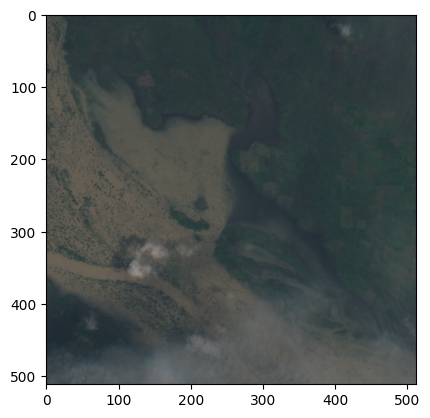

In [17]:
from auto_prompt_sam2.demo_config import load_demo_config
from auto_prompt_sam2.demo_backend import DemoBackend
from auto_prompt_sam2.demo_images import load_image, S2_LAYOUT
cfg=load_demo_config(environ={**os.environ,'DEMO_MODE':'inference','DEMO_ALLOW_DOWNLOAD':'1'})
be=DemoBackend(cfg)
img=load_image('/content/chip.tif',S2_LAYOUT,be.params)
print(img.rgb.shape, 'válidos', int(img.valid.sum()))
# Puntos manuales (x,y,etiqueta): ajustar tras mirar img.preview(); 1=agua, 0=fondo. Deben caer en píxeles válidos.
import matplotlib.pyplot as plt; plt.imshow(img.preview()); plt.show()

In [18]:
POINTS=[(256,256,1),(100,100,0)]   # EDITAR: al menos un positivo sobre agua visible
out=be.segment(img,POINTS,compare=False)
m=out['frozen']['mask']; print('píxeles de máscara:',int(m.sum()),'estado:',out['status'])
assert m.dtype==bool and m.shape==img.valid.shape and m.sum()>0,'La máscara salió vacía: mover los puntos'
from PIL import Image; Image.fromarray((m*255).astype('uint8')).save('/content/e3_demo_mask.png')
json.dump({'points':POINTS,'mask_pixels':int(m.sum()),'selection':str(out['frozen']['selection']),'gpu':torch.cuda.get_device_name(0),
  'chip_sha256':hashlib.sha256(open('/content/chip.tif','rb').read()).hexdigest(),'checkpoint':'facebook/sam2.1-hiera-tiny (verificado por SHA contra report.json)'},open('/content/e3_demo_smoke.json','w'),indent=1)
print('OK e3_demo_smoke')

sam2.1_hiera_tiny.pt: reconstructing file:   0%|          |  0.00B /  156MB            

sam2.1_hiera_tiny.pt: downloading bytes:           |  0.00B            

píxeles de máscara: 23252 estado: Comparación desactivada por el usuario
OK e3_demo_smoke


**Guardar:** descarga el JSON y conserva la máscara en Drive privado mientras se aclara la licencia del dataset.


## Recorrido real desde Gradio (GPU)

Esta sección sí requiere ejecutar el notebook en Colab con GPU y usar la revisión de código que contiene la integración actual. El smoke test de backend anterior no sustituye estos clics. Se guardarán los resultados reales en Drive, sin incluir etiquetas ni tokens. Antes de continuar, monta Drive y configura `DEMO_AUTO_BUNDLE` con `official_complete_bundle` de stage5 para probar también el modo automático. Si no lo configuras, prueba la ruta Manual; no se registrarán predicciones automáticas.

In [21]:
from pathlib import Path
from zipfile import ZipFile
import importlib

repo = Path("/content/auto-prompt-sam2-e3-demo")
archive = Path("/content/auto-prompt-sam2-demo-source.zip")
assert archive.is_file(), f"No encuentro el ZIP en {archive}"

with ZipFile(archive) as z:
    z.extractall(repo)

import auto_prompt_sam2.demo_ui as demo_ui
demo_ui = importlib.reload(demo_ui)
DemoController = demo_ui.DemoController
build_demo = demo_ui.build_demo

print("UI actualizada desde:", archive)
print("Gradio Image acepta buttons:", "buttons" in __import__("inspect").signature(
    __import__("gradio").Image
).parameters)

UI actualizada desde: /content/auto-prompt-sam2-demo-source.zip
Gradio Image acepta buttons: True


In [22]:
import hashlib, json, logging, platform, subprocess
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
from datetime import datetime, timezone
from pathlib import Path
from PIL import Image
import numpy as np
from auto_prompt_sam2.demo_ui import DemoController, build_demo
from auto_prompt_sam2.artifacts import sha256_file

# Opcional para probar DINOv3. El JSON debe ser official_complete_bundle de stage5.
# os.environ["DEMO_AUTO_BUNDLE"] = "/content/drive/MyDrive/auto-prompt-sam2/demo/official_complete_bundle.json"
# Usa Colab Secrets para HF_TOKEN si DINOv3 requiere autorización.
try:
    from google.colab import userdata
    if userdata.get("HF_TOKEN"): os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass
os.environ["DEMO_MODE"] = "inference"
os.environ["DEMO_ALLOW_DOWNLOAD"] = "1"
cfg = load_demo_config(environ=os.environ)
run_dir = Path('/content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
run_dir.mkdir(parents=True, exist_ok=False)
records_path = run_dir / 'results.json'
log_path = run_dir / 'gradio.log'
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(name)s %(message)s',
                    handlers=[logging.FileHandler(log_path, encoding='utf-8'), logging.StreamHandler()], force=True)
class EvidenceController(DemoController):
    def segment(self, image, points, compare, strategy='Manual'):
        output = super().segment(image, points, compare, strategy)
        overlay, tuned_overlay, frozen_mask, tuned_mask, details, status = output
        index = len(json.loads(records_path.read_text()) if records_path.exists() else []) + 1
        saved = {}
        for name, value in [('frozen_mask', frozen_mask), ('tuned_mask', tuned_mask),
                            ('frozen_overlay', overlay), ('tuned_overlay', tuned_overlay)]:
            if value is not None:
                path = run_dir / f'{index:02d}_{name}.png'
                Image.fromarray(np.asarray(value).astype('uint8')).save(path)
                saved[name] = {'file': path.name, 'sha256': sha256_file(path),
                               'positive_pixels': int((np.asarray(value) > 0).sum()) if 'mask' in name else None}
        record = {'index': index, 'timestamp_utc': datetime.now(timezone.utc).isoformat(),
                  'commit': subprocess.run(['git','rev-parse','HEAD'], capture_output=True, text=True).stdout.strip(),
                  'python': platform.python_version(), 'gpu': __import__('torch').cuda.get_device_name(0),
                  'strategy': strategy, 'status': status, 'details': details,
                  'sam_checkpoint_sha256': self.report['model']['checkpoint_sha256'],
                  'source_sha256': {name: sha256_file(Path('src/auto_prompt_sam2') / name) for name in
                      ['demo_backend.py','demo_ui.py','demo_images.py','automatic_prompts.py','probe.py','features.py','preprocessing.py']},
                  'automatic_bundle_sha256': (sha256_file(cfg['automatic_bundle_path'])
                      if cfg.get('automatic_bundle_path') and Path(cfg['automatic_bundle_path']).is_file() else None),
                  'files': saved}
        records = json.loads(records_path.read_text()) if records_path.exists() else []
        records.append(record)
        records_path.write_text(json.dumps(records, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
        logging.getLogger('demo.evidence').info('GRADIO_RESULT %s', json.dumps(record, ensure_ascii=False))
        return output

controller = EvidenceController(cfg)
demo = build_demo(cfg, controller=controller)
server = demo.launch(share=True, prevent_thread_lock=True, show_error=True)
print('Abre la URL temporal de Gradio y completa las pruebas manual/automática.')
print('Carpeta de resultados:', run_dir)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2026-11-19 05:16:29,538 INFO httpx HTTP Request: GET http://127.0.0.1:7860/gradio_api/startup-events "HTTP/1.1 200 OK"
2026-11-19 05:16:29,572 INFO httpx HTTP Request: HEAD http://127.0.0.1:7860/ "HTTP/1.1 200 OK"


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()


2026-11-19 05:16:29,903 INFO httpx HTTP Request: GET https://api.gradio.app/v3/tunnel-request "HTTP/1.1 200 OK"
2026-11-19 05:16:30,032 INFO httpx HTTP Request: GET https://cdn-media.huggingface.co/frpc-gradio-0.3/frpc_linux_amd64 "HTTP/1.1 200 OK"


* Running on public URL: https://1d5c8cd2801754a7ad.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


2026-11-19 05:16:30,632 INFO httpx HTTP Request: HEAD https://1d5c8cd2801754a7ad.gradio.live "HTTP/1.1 200 OK"


Abre la URL temporal de Gradio y completa las pruebas manual/automática.
Carpeta de resultados: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T051627Z


In [30]:
demo.close()

Closing server running on port: 7860


In [25]:
from pathlib import Path

bundle = Path(
    "/content/drive/MyDrive/auto-prompt-sam2/stage5/environment/runs/"
    "20261029T194653Z_8073c068fa_ed6583db/official_complete_bundle/"
    "20261029T202402773328Z_19682f232c35/payload"
)
print("Bundle encontrado:", bundle.is_file())
assert bundle.is_file(), "No aparece ese run de stage5 en tu Drive."

cfg["automatic_bundle_path"] = str(bundle)

Bundle encontrado: True


In [24]:
import hashlib, json, logging, platform, subprocess
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
from datetime import datetime, timezone
from pathlib import Path
from PIL import Image
import numpy as np
from auto_prompt_sam2.demo_ui import DemoController, build_demo
from auto_prompt_sam2.artifacts import sha256_file

# Opcional para probar DINOv3. El JSON debe ser official_complete_bundle de stage5.
os.environ["DEMO_AUTO_BUNDLE"] = "/content/drive/MyDrive/auto-prompt-sam2/demo/official_complete_bundle.json"
# Usa Colab Secrets para HF_TOKEN si DINOv3 requiere autorización.
try:
    from google.colab import userdata
    if userdata.get("HF_TOKEN"): os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass
os.environ["DEMO_MODE"] = "inference"
os.environ["DEMO_ALLOW_DOWNLOAD"] = "1"
cfg = load_demo_config(environ=os.environ)
run_dir = Path('/content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
run_dir.mkdir(parents=True, exist_ok=False)
records_path = run_dir / 'results.json'
log_path = run_dir / 'gradio.log'
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(name)s %(message)s',
                    handlers=[logging.FileHandler(log_path, encoding='utf-8'), logging.StreamHandler()], force=True)
class EvidenceController(DemoController):
    def segment(self, image, points, compare, strategy='Manual'):
        output = super().segment(image, points, compare, strategy)
        overlay, tuned_overlay, frozen_mask, tuned_mask, details, status = output
        index = len(json.loads(records_path.read_text()) if records_path.exists() else []) + 1
        saved = {}
        for name, value in [('frozen_mask', frozen_mask), ('tuned_mask', tuned_mask),
                            ('frozen_overlay', overlay), ('tuned_overlay', tuned_overlay)]:
            if value is not None:
                path = run_dir / f'{index:02d}_{name}.png'
                Image.fromarray(np.asarray(value).astype('uint8')).save(path)
                saved[name] = {'file': path.name, 'sha256': sha256_file(path),
                               'positive_pixels': int((np.asarray(value) > 0).sum()) if 'mask' in name else None}
        record = {'index': index, 'timestamp_utc': datetime.now(timezone.utc).isoformat(),
                  'commit': subprocess.run(['git','rev-parse','HEAD'], capture_output=True, text=True).stdout.strip(),
                  'python': platform.python_version(), 'gpu': __import__('torch').cuda.get_device_name(0),
                  'strategy': strategy, 'status': status, 'details': details,
                  'sam_checkpoint_sha256': self.report['model']['checkpoint_sha256'],
                  'source_sha256': {name: sha256_file(Path('src/auto_prompt_sam2') / name) for name in
                      ['demo_backend.py','demo_ui.py','demo_images.py','automatic_prompts.py','probe.py','features.py','preprocessing.py']},
                  'automatic_bundle_sha256': (sha256_file(cfg['automatic_bundle_path'])
                      if cfg.get('automatic_bundle_path') and Path(cfg['automatic_bundle_path']).is_file() else None),
                  'files': saved}
        records = json.loads(records_path.read_text()) if records_path.exists() else []
        records.append(record)
        records_path.write_text(json.dumps(records, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
        logging.getLogger('demo.evidence').info('GRADIO_RESULT %s', json.dumps(record, ensure_ascii=False))
        return output

controller = EvidenceController(cfg)
demo = build_demo(cfg, controller=controller)
server = demo.launch(share=True, prevent_thread_lock=True, show_error=True)
print('Abre la URL temporal de Gradio y completa las pruebas manual/automática.')
print('Carpeta de resultados:', run_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2026-11-19 05:26:00,254 INFO httpx HTTP Request: GET http://127.0.0.1:7860/gradio_api/startup-events "HTTP/1.1 200 OK"
2026-11-19 05:26:00,277 INFO httpx HTTP Request: HEAD http://127.0.0.1:7860/ "HTTP/1.1 200 OK"


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()


2026-11-19 05:26:00,480 INFO httpx HTTP Request: GET https://api.gradio.app/v3/tunnel-request "HTTP/1.1 200 OK"


* Running on public URL: https://0c263fa38fe1f97f56.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


2026-11-19 05:26:00,867 INFO httpx HTTP Request: HEAD https://0c263fa38fe1f97f56.gradio.live "HTTP/1.1 200 OK"


Abre la URL temporal de Gradio y completa las pruebas manual/automática.
Carpeta de resultados: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T052559Z


In [29]:
print("Log:", log_path)
print(log_path.read_text(encoding="utf-8", errors="replace")[-12000:])

Log: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T052559Z/gradio.log
1", "demo_ui.py": "57366333b92de12e7853ee6531ca098008ee6b6a43d6a586cdf322b6b19bb41c", "demo_images.py": "f5e57d25f09e594d10168a9a621a4a70e4514bff030ab99d078b8d42300c5a63", "automatic_prompts.py": "b7f93281917a58533ce42ac6301c62dca56cf8ae50ea0a34357eb8976d7a7c40", "probe.py": "beb03e0e76feb6e1c15a13323edeae07e23b4a3959fd3515ce35b53dcc19b731", "features.py": "174e0ac2bbbad0d5f8a09cbc6fc1f40a38aa9b9887824f6822a3954cda2202a7", "preprocessing.py": "bcc94f5d53b0393fb3319c65a2ed486e040aa6b7c981ff10d9b54f910e0246ba"}, "automatic_bundle_sha256": null, "files": {}}
2026-11-19 05:26:34,338 INFO auto_prompt_sam2.demo_ui Falta un artefacto de inferencia: [Errno 2] No such file or directory: '/content/drive/MyDrive/auto-prompt-sam2/demo/official_complete_bundle.json'
2026-11-19 05:26:34,359 INFO demo.evidence GRADIO_RESULT {"index": 2, "timestamp_utc": "2026-11-19T05:26:34.343718+00:00", "commit": "", "python":

### Pasos de aceptación en el navegador

1. Sube un GeoTIFF Sentinel‑2 de validación de 512×512. En **Manual**, coloca un punto positivo y uno negativo y pulsa **Segmentar**; verifica máscara, superposición y descarga PNG.
2. Cambia a **Automático · DINOv3 → SAM**, vuelve a segmentar sin usar puntos manuales y verifica que el detalle muestre puntos/probe/umbral y que aparezca la máscara. Este paso necesita bundle stage5 y permiso de HF para DINOv3.
3. Al terminar, ejecuta la celda siguiente. El registro distingue ambos recorridos; una celda sin interacción no acredita la aceptación.

In [33]:
demo.close()
print('Evidencia persistida en:', run_dir)
print('JSON:', records_path, 'bytes:', records_path.stat().st_size if records_path.exists() else 0)
print('Log:', log_path, 'bytes:', log_path.stat().st_size if log_path.exists() else 0)
print('Archivos:', sorted(p.name for p in run_dir.iterdir()))
assert records_path.is_file() and json.loads(records_path.read_text()), 'Interactúa con la UI antes de cerrar el servidor.'


Evidencia persistida en: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T052559Z
JSON: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T052559Z/results.json bytes: 3857
Log: /content/drive/MyDrive/auto-prompt-sam2/demo_gradio_runs/20261119T052559Z/gradio.log bytes: 13209
Archivos: ['gradio.log', 'results.json']
